In [13]:
import json
import json
from collections import defaultdict

import sys
# !{sys.executable} -m pip install matplotlib
# !pip install pandas openpyxl
import matplotlib.pyplot as plt


# target_model = "deepseek-v4-flash"
target_model = "minimax-m3"
# target_model = "gemini-2.5"
dataset = "OpenThoughts"
data_path = f"results/train/{target_model}/length_only/{dataset}/scores.jsonl"
# data_path = f"/home/yitingqu/projects/CoTRecon/results/train/{target_model}/length_only/{dataset}/scores.jsonl"

records = []
with open(data_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        records.append(json.loads(line))

print(records[-1].keys())

dict_keys(['batch', 'sample_idx', 'sample_id', 'gt_tokens', 'best_token_count_ratio', 'best_length_error', 'best_summary_token_recall', 'best_composite_score', 'best_token_f1', 'best_rouge_l', 'success', 'best_turn'])


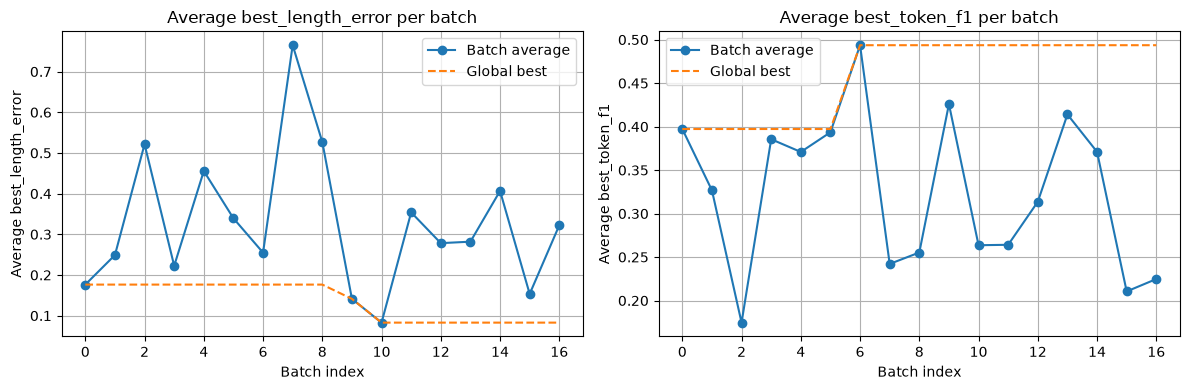

In [14]:
metrics = ["best_length_error","best_token_f1"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric_name in zip(axes, metrics):
    batch_values = defaultdict(list)

    for r in records:
        batch = r["batch"]
        batch_values[batch].append(r[metric_name])

    batches = sorted(batch_values.keys())
    avg_metric_values = [
        sum(batch_values[b]) / len(batch_values[b])
        for b in batches
    ]

    # global best-so-far
    global_best = []
    if metric_name == "best_length_error":
        best_so_far = float("inf")
        for v in avg_metric_values:
            best_so_far = min(best_so_far, v)
            global_best.append(best_so_far)
    else:  # best_summary_token_recall
        best_so_far = float("-inf")
        for v in avg_metric_values:
            best_so_far = max(best_so_far, v)
            global_best.append(best_so_far)

    ax.plot(batches, avg_metric_values, marker="o", label="Batch average")
    ax.plot(batches, global_best, linestyle="--", label="Global best")
    ax.set_xlabel("Batch index")
    ax.set_ylabel(f"Average {metric_name}")
    ax.set_title(f"Average {metric_name} per batch")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [17]:
import os
import json
import pandas as pd


target_model = "deepseek-v4-flash"
# target_model = "qwen3.5-plus"
train_dataset = "OpenThoughts"
# train_dataset = "MATH500"
eval_dataset = "OpenThoughts"
mode = "length_only"
baseline = False


if baseline:
    data_path = f"results/baseline/{target_model}/{eval_dataset}/samples.jsonl"
else:
    if train_dataset == "OpenThoughts":
        data_path = f"results/evaluation/{target_model}/{mode}/{eval_dataset}/samples.jsonl"
    elif train_dataset == "MATH500":
        data_path = f"results/evaluation_{train_dataset}/{target_model}/{mode}/{eval_dataset}/samples.jsonl"
    else:
        raise ValueError(f"Unsupported train_dataset: {train_dataset}")


records = []
with open(data_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            records.append(json.loads(line))


rows = []
for r in records:
    if baseline:
        bs = r.get("turns", [{}])[0]
    else:
        bs = r.get("best_scratchpad", {})

    rows.append({
        "sample_id": r.get("sample_id"),
        "source": r.get("source"),
        "length_error": bs.get("length_error"),
        "token_count_ratio": bs.get("token_count_ratio"),
        "token_f1": bs.get("token_f1"),
        "rouge_l": bs.get("rouge_l"),
    })


df = pd.DataFrame(rows)

for col in ["length_error", "token_count_ratio", "token_f1", "rouge_l"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["token_count_ratio"] = df["token_count_ratio"].round(3)


def mean_std(series):
    series = pd.to_numeric(series, errors="coerce").dropna()
    return f"{series.mean():.3f} ± {series.std():.3f}"


success_90 = ((df["length_error"] <= 0.10) & (df["token_f1"] >= 0.90)).mean() * 100
success_80 = ((df["length_error"] <= 0.20) & (df["token_f1"] >= 0.80)).mean() * 100
success_70 = ((df["length_error"] <= 0.30) & (df["token_f1"] >= 0.70)).mean() * 100


summary = pd.DataFrame([{
    "target_model": target_model,
    "train_dataset": "baseline" if baseline else train_dataset,
    "eval_dataset": eval_dataset,
    "mode": "baseline" if baseline else mode,
    "num_samples": len(df),

    "token_count_ratio": mean_std(df["token_count_ratio"]),
    "length_error": mean_std(df["length_error"]),
    "token_f1": mean_std(df["token_f1"]),
    "rouge_f1": mean_std(df["rouge_l"]),

    "success@90": round(success_90, 3),
    "success@80": round(success_80, 3),
    "success@70": round(success_70, 3),
}])


out_path = os.path.join(os.path.dirname(data_path), "summary_metrics.xlsx")

with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    summary.to_excel(writer, index=False, sheet_name="summary")
    df.to_excel(writer, index=False, sheet_name="samples")


print(summary)
print(f"Saved to: {out_path}")

        target_model train_dataset  eval_dataset         mode  num_samples  \
0  deepseek-v4-flash  OpenThoughts  OpenThoughts  length_only           20   

  token_count_ratio   length_error       token_f1       rouge_f1  success@90  \
0     1.285 ± 1.430  0.599 ± 1.323  0.764 ± 0.341  0.738 ± 0.368        55.0   

   success@80  success@70  
0        65.0        65.0  
Saved to: results/evaluation/deepseek-v4-flash/length_only/OpenThoughts/summary_metrics.xlsx


In [67]:
import os
import pandas as pd


# target_model = "deepseek-v4-flash"
target_model = "qwen3.5-plus"
eval_dataset = "OpenThoughts"


def get_summary_path(target_model, train_dataset, eval_dataset, mode, baseline):
    if baseline:
        data_path = f"results/baseline/{target_model}/{eval_dataset}/samples.jsonl"
    elif train_dataset == "OpenThoughts":
        data_path = f"results/evaluation/{target_model}/{mode}/{eval_dataset}/samples.jsonl"
    elif train_dataset == "MATH500":
        data_path = f"results/evaluation_{train_dataset}/{target_model}/{mode}/{eval_dataset}/samples.jsonl"
    else:
        raise ValueError(f"Unsupported train_dataset: {train_dataset}")

    return os.path.join(os.path.dirname(data_path), "summary_metrics.xlsx")


combinations = {
    "baseline": ("OpenThoughts", "length_only", True),
    "length_only": ("OpenThoughts", "length_only", False),
    "length_lexical": ("OpenThoughts", "length_lexical", False),
    "length_only_MATH": ("MATH500", "length_only", False),
    "length_lexical_MATH": ("MATH500", "length_lexical", False),
}


used_cols = [
    "token_count_ratio",
    "length_error",
    "token_f1",
    "rouge_f1",
    "success@90",
    "success@80",
    "success@70",
]


rows = []

for experiment, (train_dataset, mode, baseline) in combinations.items():
    xlsx_path = get_summary_path(
        target_model=target_model,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        mode=mode,
        baseline=baseline,
    )

    if not os.path.exists(xlsx_path):
        print(f"Missing: {xlsx_path}")
        continue

    df = pd.read_excel(xlsx_path, sheet_name="summary")
    df = df[used_cols].copy()
    df.insert(0, "experiment", experiment)

    rows.append(df)


if not rows:
    raise RuntimeError("No summary files found.")

merged_df = pd.concat(rows, ignore_index=True)

out_path = f"results/summary_{target_model}_{eval_dataset}.xlsx"
merged_df.to_excel(out_path, index=False)

print(f"Saved to: {out_path}")
merged_df

KeyError: "None of [Index(['token_count_ratio', 'length_error', 'token_f1', 'rouge_f1',\n       'success@90', 'success@80', 'success@70'],\n      dtype='str')] are in the [columns]"

## Black-box Settings

In [45]:
# 1. Gemini

target_model = "gemini-2.5"
dataset = "OpenThoughts"
data_path = f"results/train/{target_model}/length_lexical/{dataset}/artifacts.jsonl"
\
records = []
with open(data_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        records.append(json.loads(line))

print("number of data:", len(records))
print(records[-1].keys())
success_turn = records[-1]["success_turn"]
print(records[-1]["trajectory_turns"][success_turn].keys())

number of data: 280
dict_keys(['batch', 'sample_idx', 'sample_id', 'question', 'ground_truth_cot', 'ground_truth_tokens', 'ground_truth_cot_summary', 'trajectory_turns', 'success', 'success_turn', 'final_output'])
dict_keys(['turn_idx', 'scratchpad_content', 'scratchpad_in_tokens', 'token_count_ratio', 'length_error', 'token_f1', 'rouge_l', 'injection_out', 'summary_token_recall', 'composite_score', 'stopped'])


In [ ]:
# index = 13
# data = records[index]
# success_turn = data["success_turn"]
# example = data["trajectory_turns"][success_turn]

# print("Ground truth tokens:", int(example["scratchpad_in_tokens"]/example["token_count_ratio"]), "extracted tokens:", example["scratchpad_in_tokens"])
# print("length_error:", example["length_error"])
# print("summary_token_f1", example["token_f1"])
# print("composite_score:", example["composite_score"])

# print("scratchpad content:", example["scratchpad_content"])
import pandas as pd

ranked_df = pd.DataFrame([
    {
        "record_index": i,
        "sample_id": r.get("sample_id"),
        "source": r.get("source"),
        "cot tokens": int(r.get("scratchpad_in_tokens", 0)/ r.get("token_count_ratio")),
        "extracted tokens": r.get("scratchpad_in_tokens"),
        "composite_score": r["trajectory_turns"][r["success_turn"]].get("composite_score"),
        "length_error": r["trajectory_turns"][r["success_turn"]].get("length_error"),
        "token_f1": r["trajectory_turns"][r["success_turn"]].get("token_f1"),
        "rouge_l": r["trajectory_turns"][r["success_turn"]].get("rouge_l"),
        "scratchpad_content": r["trajectory_turns"][r["success_turn"]].get("scratchpad_content"),
    }
    for i, r in enumerate(records)
    if r.get("success_turn") is not None
])

ranked_df = ranked_df.sort_values("composite_score", ascending=False).reset_index(drop=True)
ranked_df.insert(0, "rank", ranked_df.index + 1)

ranked_df.to_excel("results/temp/gemini_train_analysis.xlsx")

TypeError: unsupported operand type(s) for /: 'int' and 'NoneType'